Malwer Detection

In [ ]:
import os
import hashlib
import math

In [ ]:
def calculate_entropy(file_path):
    """Calculate the entropy of a file."""
    with open(file_path, 'rb') as f:
        byte_arr = list(f.read())
        file_size = len(byte_arr)
        if file_size == 0:
            return 0
        freq_list = [0] * 256
        for b in byte_arr:
            freq_list[b] += 1
        freq_list = [float(x) / file_size for x in freq_list]
        entropy = -sum([p * math.log(p, 2) for p in freq_list if p > 0])
        return entropy


In [ ]:
def get_hashes(file_path):
    """Generate MD5 and SHA256 hashes of a file."""
    with open(file_path, "rb") as f:
        file_bytes = f.read()
        file_md5 = hashlib.md5(file_bytes).hexdigest()
        file_sha256 = hashlib.sha256(file_bytes).hexdigest()
    return file_md5, file_sha256

In [ ]:
def extract_file_features(file_path):
    """Extract the 6 selected features from a file."""
    try:
        # Feature 1: File size (usage_counter)
        file_size = os.path.getsize(file_path)

        # Feature 2: File entropy (fs_excl_counter)
        file_entropy = calculate_entropy(file_path)

        # Feature 3: File is an executable (task_size)
        file_extension = os.path.splitext(file_path)[1]
        is_exe = 1 if file_extension == '.exe' else 0

        # Feature 4: Time since last accessed (end_data)
        last_accessed = os.path.getatime(file_path)

        # Feature 5: Time since last modified (policy)
        last_modified = os.path.getmtime(file_path)

        # Feature 6: Time since file creation (nivcsw)
        created = os.path.getctime(file_path)

        # Combine the 6 features into a dictionary
        features = {
            'usage_counter': file_size,  # usage_counter
            'fs_excl_counter': file_entropy,  # fs_excl_counter
            'task_size': is_exe,  # task_size
            'end_data': last_accessed,  # end_data
            'policy': last_modified,  # policy
            'nivcsw': created  # nivcsw
        }

        return features

    except Exception as e:
        print(f"Error extracting features from {file_path}: {e}")
        return None

In [ ]:
import pandas as pd
from pathlib import Path
import sys
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import joblib

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "logging_config.py").is_file():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from logging_config import setup_logging

notebook_logger = setup_logging(
    str(PROJECT_ROOT / "logs" / "malware_detection_notebook.log")
)

In [ ]:
dataset_path = PROJECT_ROOT / "dataset" / "malwareDataset.csv"
if not dataset_path.is_file():
    raise FileNotFoundError(f"Malware dataset not found: {dataset_path}")
dataset = pd.read_csv(dataset_path)
print(f"Loaded {len(dataset):,} malware records from {dataset_path}")

In [ ]:
# Keep only the top 6 features
selected_features = [
    'usage_counter', 'fs_excl_counter', 'task_size',
    'end_data', 'policy', 'nivcsw'
]

# Drop rows where any of our selected features or the classification target are NaN
cleaned_dataset = dataset.dropna(subset=selected_features + ['classification']).copy()
cleaned_dataset['classification'] = (
    cleaned_dataset['classification'].astype(str).str.strip().str.lower()
)

# Filter the dataset to keep only the selected features and the label
X = cleaned_dataset[selected_features]
y = cleaned_dataset['classification']

# Split dataset into training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# Scale the selected features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train the Random Forest model
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train_scaled, y_train)

# Save the updated model and scaler
joblib.dump(model, 'malware_detection_model_selected_features.pkl')
joblib.dump(scaler, 'scaler_selected_features.pkl')

print(f"Model successfully trained on {len(X_train)} samples and saved with selected 6 features.")

Model successfully trained on 12875 samples and saved with selected 6 features.


## Model Comparison (Updated)
We will train **Gradient Boosting**, **K-Neighbors (KNN)**, **Decision Tree**, and **AdaBoost** classifiers. We will then compare their performance metrics against our baseline **Random Forest** model.

In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Initialize the models (Removing SVM, adding 3 new powerful classifiers)
models = {
    "Random Forest": model,  # our pre-trained random forest
    "Gradient Boosting": HistGradientBoostingClassifier(random_state=42),
    "K-Neighbors (KNN)": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "AdaBoost": AdaBoostClassifier(random_state=42)
}

# List to hold evaluation results
comparison_results = []

# Train and evaluate each model
for name, clf in models.items():
    if name != "Random Forest":
        print(f"Training {name}...")
        clf.fit(X_train_scaled, y_train)

    # Predict
    predictions = clf.predict(X_test_scaled)

    # Calculate metrics
    acc = accuracy_score(y_test, predictions)
    prec = precision_score(y_test, predictions, pos_label='malware', zero_division=0)
    rec = recall_score(y_test, predictions, pos_label='malware', zero_division=0)
    f1 = f1_score(y_test, predictions, pos_label='malware', zero_division=0)

    comparison_results.append({
        "Model": name,
        "Accuracy": acc,
        "Malware Precision": prec,
        "Malware Recall": rec,
        "Malware F1-Score": f1
    })
    notebook_logger.info(
        "event=malware_model_evaluation_completed model=%s "
        "metric_accuracy=%.6f metric_precision=%.6f "
        "metric_recall=%.6f metric_f1=%.6f test_rows=%d",
        name.replace(" ", "_"), acc, prec, rec, f1, len(y_test)
    )

# Convert results to DataFrame
results_df = pd.DataFrame(comparison_results)
display(results_df)

Training Gradient Boosting...
Training K-Neighbors (KNN)...
Training Decision Tree...
Training AdaBoost...


,Model,Accuracy,Malware Precision,Malware Recall,Malware F1-Score
0,Random Forest,0.904494,0.871116,0.645904,0.741793
1,Gradient Boosting,0.904494,0.871116,0.645904,0.741793
2,K-Neighbors (KNN),0.904494,0.871116,0.645904,0.741793
3,Decision Tree,0.904494,0.871116,0.645904,0.741793
4,AdaBoost,0.862994,0.774406,0.500853,0.608290


### Visualizing the Model Comparison

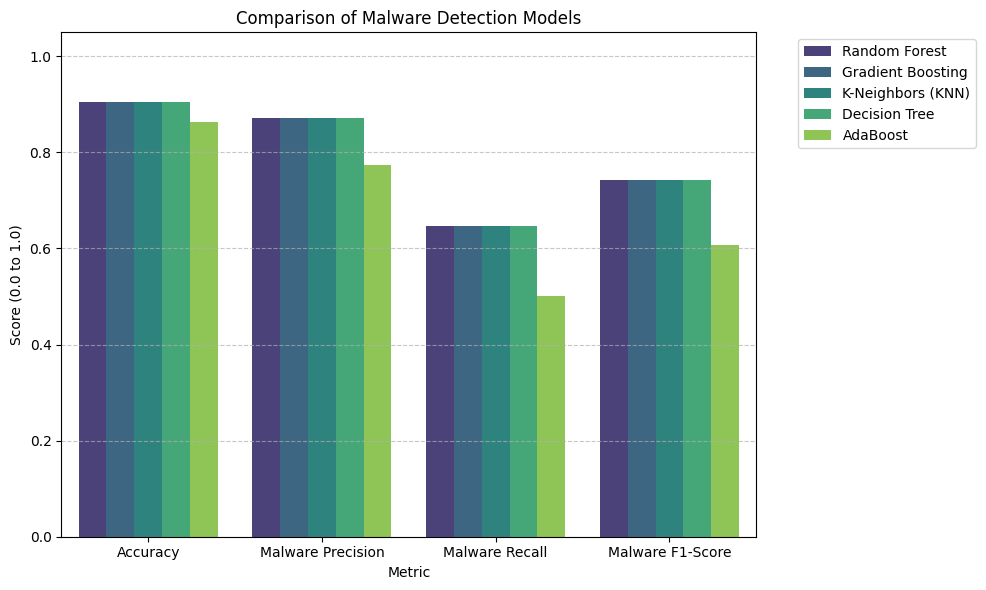

In [ ]:
# Reshape the dataframe for easy plotting with seaborn
plot_data = pd.melt(results_df, id_vars="Model", var_name="Metric", value_name="Value")

plt.figure(figsize=(10, 6))
sns.barplot(data=plot_data, x="Metric", y="Value", hue="Model", palette="viridis")
plt.title("Comparison of Malware Detection Models")
plt.ylabel("Score (0.0 to 1.0)")
plt.ylim(0, 1.05)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [ ]:
#scaninng files

import joblib
import os

# Load the trained model and scaler
model = joblib.load('malware_detection_model_selected_features.pkl')
scaler = joblib.load('scaler_selected_features.pkl')


In [ ]:
def scan_directory(directory_path):
    """Scan all files in a directory for malware."""
    for root, dirs, files in os.walk(directory_path):
        for file in files:
            file_path = os.path.join(root, file)
            features = extract_file_features(file_path)
            if features is not None:
                # Extract feature values from the dictionary
                feature_values = list(features.values())

                # Reshape and scale the feature values
                features_scaled = scaler.transform([feature_values])

                # Predict if the file is malware
                prediction = model.predict(features_scaled)
                if prediction == 1:
                    print(f"Malware detected: {file_path}")
                else:
                    print(f"Clean file: {file_path}")
            else:
                print(f"Error scanning {file_path}")

In [39]:
directory_path = input("Enter the directory path to scan for malware: ")
scan_directory(directory_path)

Enter the directory path to scan for malware: ./test.png



```
Clean file: ./malwareDataset.csv
Clean file: ./scaler_selected_features.pkl
Clean file: ./malware_detection_model_selected_features.pkl
Clean file: ./.config/active_config
Clean file: ./.config/hidden_gcloud_config_universe_descriptor_data_cache_configs.db
Clean file: ./.config/config_sentinel
Clean file: ./.config/.last_update_check.json
Clean file: ./.config/default_configs.db
Clean file: ./.config/.last_opt_in_prompt.yaml
Clean file: ./.config/gce
Clean file: ./.config/.last_survey_prompt.yaml
Clean file: ./.config/configurations/config_default
Clean file: ./.config/logs/2026.10.02/13.50.15.366402.log
Clean file: ./.config/logs/2026.10.02/13.50.08.874802.log
Clean file: ./.config/logs/2026.10.02/13.50.21.555054.log
Clean file: ./.config/logs/2026.10.02/13.49.46.128557.log
Clean file: ./.config/logs/2026.10.02/13.50.14.261149.log
Clean file: ./.config/logs/2026.10.02/13.50.21.004336.log
Clean file: ./sample_data/anscombe.json
Clean file: ./sample_data/README.md
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
Clean file: ./sample_data/mnist_train_small.csv
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
Clean file: ./sample_data/california_housing_train.csv
Clean file: ./sample_data/california_housing_test.csv
Clean file: ./sample_data/mnist_test.csv
```